# Allocation Misspecification Diagnostics

Two supplied exposure systems produce two constrained portfolios and a reference-system exposure error:

$$
w_R=w^{\star}(V,B_R,c_R),
\qquad
w_M=w^{\star}(V,B_M,c_M),
\qquad
e_R=B_R^{\mathsf T}w_M-c_R.
$$

Here, $V$ is the common covariance matrix, $B_R$ and $c_R$ are the reference exposure matrix and target vector, $B_M$ and $c_M$ are the misspecified exposure matrix and its target vector, $w_R$ and $w_M$ are their minimum-variance weights, and $e_R$ measures the exposures produced by $w_M$ when evaluated in the reference system.

## Notebook setup

### Number formatting for tables

In [ ]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display

def compact_float_format(number_format=None):

    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value

def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch('[+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?', rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return '0'
    if ('.' in rendered or 'e' in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered

def compact_numeric_text(text):
    pattern = '(?<![0-9.eE])([+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])'
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)



### Packages and notebook settings

In [ ]:
from pathlib import Path as _FigurePath
from sys import path as _figure_import_path

_figure_folder = _FigurePath.cwd()
_figure_root = next(
    folder for folder in (_figure_folder, *_figure_folder.parents)
    if (folder / "notebook_figures.py").is_file()
)
_figure_import_path.insert(0, str(_figure_root))
from notebook_figures import display_notebook_figure

def compact_table_latex(latex):
    return compact_numeric_text(latex)

def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + '</div>'

def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)
from pathlib import Path
from dataclasses import FrozenInstanceError, fields
import inspect
import math
import re
import sys
import warnings
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.special import ndtr
from scipy.stats import norm
warnings.filterwarnings('ignore');


### Library version and study settings

In [ ]:
ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
import io
import zipfile
DATA_URL = 'https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/49_Industry_Portfolios_daily_CSV.zip'
DATA_DIR = ROOT / 'data' / 'public' / 'ken_french'
DATA_PATH = ensure_dataset(ROOT, 'french_49_industries')
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
with zipfile.ZipFile(DATA_PATH) as archive:
    archive_name = archive.namelist()[0]
    public_lines = archive.read(archive_name).decode('latin1').splitlines()
header_row = next((index for index, line in enumerate(public_lines) if line.startswith(',Agric')))
end_row = next((index for index in range(header_row + 1, len(public_lines)) if not public_lines[index].strip()))
raw = pd.read_csv(io.StringIO('\n'.join(public_lines[header_row:end_row])))
raw = raw.rename(columns={raw.columns[0]: 'Date'})
raw['Date'] = pd.to_datetime(raw['Date'].astype(str), format='%Y%m%d')
raw = raw.set_index('Date').replace([-99.99, -999.0], np.nan) / 100.0
industry_returns = raw.loc['2019-01-01':'2025-12-31'].dropna().copy()
from RiskLabAI.causal_factor_analysis import AllocationMisspecificationDiagnostics, FDRComparisonEvidence, FDRNonIdentificationWitness, GaussianSearchAdjustedFDR, GaussianTrialMixture, MaxSelectionFamilyErrors, SelectionLevelProbabilityEvidence, allocation_misspecification_diagnostics, compare_single_and_family_fdr, conditional_upper_tail_probability, family_level_false_discovery_rate, fdr_nonidentification_witness, gaussian_max_selection_cdf, gaussian_max_selection_log_density, gaussian_max_selection_log_likelihood, gaussian_search_adjusted_false_discovery_rate, gaussian_trial_mixture_cdf, max_selection_family_errors, max_selection_null_probability, maximum_mixture_cdf, minimum_variance_factor_weights, single_trial_false_discovery_rate
FIGURES = ROOT / 'outputs' / 'figures' / '08_search_adjusted_portfolios'
TABLES = ROOT / 'outputs' / 'tables' / '08_search_adjusted_portfolios'
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
palette = {'background': '#111827', 'axes': '#111827', 'text': '#E5E7EB', 'cyan': '#38BDF8', 'amber': '#FBBF24', 'green': '#34D399', 'rose': '#FB7185', 'violet': '#C084FC', 'grid': '#374151', 'muted': '#94A3B8'}
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': palette['background'], 'axes.facecolor': palette['axes'], 'axes.edgecolor': palette['text'], 'axes.labelcolor': palette['text'], 'axes.titlecolor': palette['text'], 'xtick.color': palette['text'], 'ytick.color': palette['text'], 'text.color': palette['text'], 'grid.color': palette['grid'], 'grid.linestyle': ':', 'legend.facecolor': palette['axes'], 'legend.edgecolor': palette['grid'], 'savefig.facecolor': palette['background']});



### Table display and number formatting

In [ ]:
def display_float(value):
    if not np.isfinite(value):
        return str(value)
    nearest_integer = round(float(value))
    if np.isclose(value, nearest_integer, atol=1e-12):
        return str(int(nearest_integer))
    if abs(value) < 5e-13:
        return '0'
    return f'{value:.6f}'.rstrip('0').rstrip('.')
pd.set_option('display.float_format', display_float)

def save_table(frame, stem, caption, label, float_format='%.6f', fit=True, position='tbp'):
    table_frame = frame.copy()
    for column in table_frame.columns:
        if pd.api.types.is_bool_dtype(table_frame[column]):
            table_frame[column] = table_frame[column].map({True: 'Yes', False: 'No'})
    table_frame.to_csv(TABLES / f'{stem}.csv', index=False)
    latex = compact_table_latex(table_frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position=position))
    if fit:
        latex = latex.replace('\\begin{tabular}', '\\centering\n' + '\\begin{adjustbox}{max width=\\textwidth}' + '\n' + '\\begin{tabular}', 1).replace('\\end{tabular}', '\\end{tabular}' + '\n' + '\\end{adjustbox}', 1)
    else:
        latex = latex.replace('\\begin{tabular}', '\\centering\n' + '\\begin{tabular}', 1)
    latex = re.sub('(?<![A-Za-z])(?:nan|NaN)(?![A-Za-z])', 'Not available', latex)
    latex = re.sub('(?<![A-Za-z])inf(?![A-Za-z])', 'No finite value', latex)
    (TABLES / f'{stem}.tex').write_text(latex, encoding='utf-8')

def save_figure(figure, stem):
    figure.savefig(FIGURES / f'{stem}.png', bbox_inches='tight', dpi=300)
    figure.savefig(FIGURES / f'{stem}.pdf', bbox_inches='tight')
    display_notebook_figure(figure)
    plt.close(figure)



## Weights in the released allocation diagnostic example

In [1]:
def contract_result(name, action, expected):
    try:
        action()
        return {'Check': name, 'Expected result': expected, 'Observed result': 'Accepted', 'Passed': False}
    except Exception as error:
        return {'Check': name, 'Expected result': expected, 'Observed result': type(error).__name__, 'Passed': type(error).__name__ == expected}

def kkt_oracle(covariance, exposures, targets):
    asset_count, factor_count = exposures.shape
    system = np.block([[2.0 * covariance, exposures], [exposures.T, np.zeros((factor_count, factor_count))]])
    right_side = np.concatenate([np.zeros(asset_count), targets])
    solution = np.linalg.solve(system, right_side)
    return (solution[:asset_count], solution[asset_count:])

def portfolio_variance(covariance, weights):
    return float(weights @ covariance @ weights)

def normal_density(value, scale=1.0):
    return math.exp(-0.5 * (value / scale) ** 2) / (math.sqrt(2.0 * math.pi) * scale)
released_covariance = np.diag([1.0, 2.0, 4.0])
released_reference_exposures = np.array([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]])
released_reference_targets = np.array([0.0, 1.0])
released_misspecified_exposures = np.array([[1.0], [1.0], [-2.0]])
released_misspecified_targets = np.array([1.0])
released_result = allocation_misspecification_diagnostics(released_covariance, released_reference_exposures, released_reference_targets, released_misspecified_exposures, released_misspecified_targets)
released_weight_table = pd.DataFrame({'Asset': ['Asset 1', 'Asset 2', 'Asset 3'], 'Reference weight': released_result.reference_weights, 'Misspecified weight': released_result.misspecified_weights, 'Sign reversal': released_result.weight_sign_reversals})
save_table(released_weight_table, 'misspecification_released_weights', 'Weights in the released allocation diagnostic example.', 'tab:chapter27-misspecification-released-weights')
display(released_weight_table)
released_exposure_table = pd.DataFrame({'Reference factor': ['Factor 1', 'Factor 2'], 'Reference target': released_result.reference_target_exposures, 'Reference allocation exposure': released_result.reference_achieved_exposures, 'Misspecified allocation exposure': released_result.misspecified_reference_exposures, 'Exposure error': released_result.reference_exposure_error})
save_table(released_exposure_table, 'misspecification_released_exposures', 'Reference-system exposures in the released diagnostic example.', 'tab:chapter27-misspecification-released-exposures')
display(released_exposure_table)
released_variance_table = pd.DataFrame([{'Allocation': 'Reference system', 'Portfolio variance': released_result.reference_variance, 'Meets its declared target': np.allclose(released_result.reference_achieved_exposures, released_result.reference_target_exposures)}, {'Allocation': 'Misspecified system', 'Portfolio variance': released_result.misspecified_variance, 'Meets its declared target': np.allclose(released_result.misspecified_model_achieved_exposures, released_result.misspecified_model_target_exposures)}])
save_table(released_variance_table, 'misspecification_released_variances', 'Variance and declared-target checks for the two released allocations.', 'tab:chapter27-misspecification-released-variances')
display(released_variance_table);


,Asset,Reference weight,Misspecified weight,Sign reversal
0,Asset 1,-0.285714,0.4,True
1,Asset 2,0.714286,0.2,False
2,Asset 3,0.285714,-0.2,True


,Reference factor,Reference target,Reference allocation exposure,Misspecified allocation exposure,Exposure error
0,Factor 1,0,0,0.2,0.2
1,Factor 2,1,1,0,-1


,Allocation,Portfolio variance,Meets its declared target
0,Reference system,1.428571,True
1,Misspecified system,0.4,True


## Two assets reverse sign

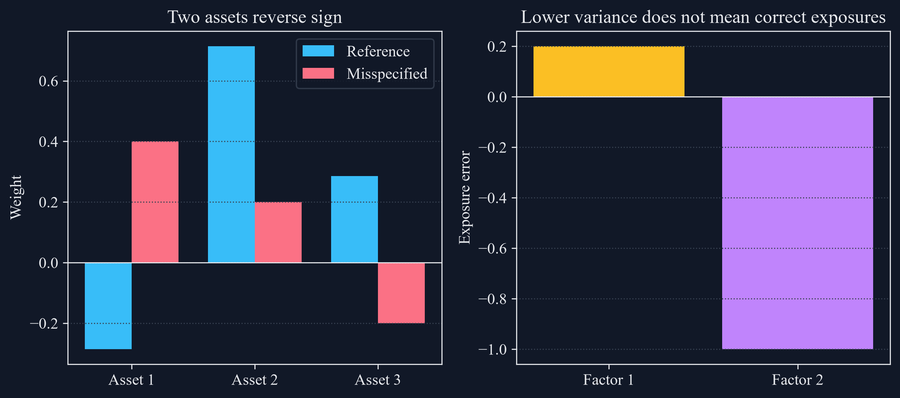

In [1]:
figure, axes = plt.subplots(1, 2, figsize=(10.8, 4.4))
locations = np.arange(3)
width = 0.38
axes[0].bar(locations - width / 2.0, released_result.reference_weights, width=width, color=palette['cyan'], label='Reference')
axes[0].bar(locations + width / 2.0, released_result.misspecified_weights, width=width, color=palette['rose'], label='Misspecified')
axes[0].axhline(0.0, color=palette['text'], linewidth=0.8)
axes[0].set_xticks(locations)
axes[0].set_xticklabels(['Asset 1', 'Asset 2', 'Asset 3'])
axes[0].set_ylabel('Weight')
axes[0].set_title('Two assets reverse sign')
axes[0].legend()
axes[0].grid(True, axis='y')
axes[1].bar(['Factor 1', 'Factor 2'], released_result.reference_exposure_error, color=[palette['amber'], palette['violet']])
axes[1].axhline(0.0, color=palette['text'], linewidth=0.8)
axes[1].set_ylabel('Exposure error')
axes[1].set_title('Lower variance does not mean correct exposures')
axes[1].grid(True, axis='y')
save_figure(figure, 'misspecification_released_example')
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': '#111827', 'axes.facecolor': '#111827', 'axes.edgecolor': '#94A3B8', 'axes.labelcolor': '#E5E7EB', 'axes.titlecolor': '#E5E7EB', 'axes.titleweight': 'bold', 'xtick.color': '#94A3B8', 'ytick.color': '#94A3B8', 'text.color': '#E5E7EB', 'grid.color': '#374151', 'grid.linestyle': ':', 'grid.linewidth': 0.8, 'legend.facecolor': '#111827', 'legend.edgecolor': '#374151', 'legend.framealpha': 0.96, 'savefig.facecolor': '#111827', 'savefig.transparent': False, 'savefig.dpi': 300, 'pdf.fonttype': 42, 'ps.fonttype': 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == '3.2.0'


## A Published Confounder Allocation

In the article's two-asset confounder example, the reference and omitted-confounder exposure systems are:

$$
B_R=
\begin{bmatrix}\gamma_1&\beta_1\\\gamma_2&\beta_2\end{bmatrix},
\qquad
B_M=
\begin{bmatrix}
\beta_1+\gamma_1\delta/(1+\delta^2)\\
\beta_2+\gamma_2\delta/(1+\delta^2)
\end{bmatrix}.
$$

Here, $\beta_n$ is asset $n$'s direct exposure to the second factor, $\gamma_n$ is its exposure to the omitted common cause, $\delta$ links the common cause to the second factor, $B_R$ keeps both reference exposure columns, and $B_M$ contains the single biased column after the common cause is omitted.

### Weights reported for the published two-asset confounder example

In [2]:
source_beta = np.array([1.0, 1.0])
source_gamma = np.array([1.0, 1.5])
source_delta = -0.5
source_reference_exposures = np.column_stack([source_gamma, source_beta])
source_reference_targets = np.array([0.0, 1.0])
source_reference_weights = np.array([3.0, -2.0])
source_reported_misspecified_weights = np.array([1.2, 0.8])
source_reference_achieved = source_reference_exposures.T @ source_reference_weights
source_reported_achieved = source_reference_exposures.T @ source_reported_misspecified_weights
source_exposure_error = source_reported_achieved - source_reference_targets
source_sign_reversals = np.signbit(source_reference_weights) != np.signbit(source_reported_misspecified_weights)

source_weight_table = pd.DataFrame({"Asset": ["Asset 1", "Asset 2"], "Reference weight": source_reference_weights, "Reported omitted-common-cause weight": source_reported_misspecified_weights, "Difference": source_reported_misspecified_weights - source_reference_weights, "Sign reversal": source_sign_reversals})
save_table(source_weight_table, "misspecification_source_weights", "Weights reported for the published two-asset confounder example.", "tab:chapter27-misspecification-source-weights")
display(source_weight_table)

source_exposure_table = pd.DataFrame({"Reference factor": ["Common cause", "Second factor"], "Target": source_reference_targets, "Reference allocation exposure": source_reference_achieved, "Reported omitted-common-cause allocation exposure": source_reported_achieved, "Exposure error": source_exposure_error})
save_table(source_exposure_table, "misspecification_source_exposures", "Direct exposure arithmetic for the allocations reported in the published confounder example.", "tab:chapter27-misspecification-source-exposures")
display(source_exposure_table)

source_check_table = pd.DataFrame({"Arithmetic check": ["Largest reference exposure error", "Reported misspecified exposure RMSE", "Number of sign reversals", "Reference gross exposure", "Reported misspecified gross exposure"], "Value": [np.max(np.abs(source_reference_achieved - source_reference_targets)), np.sqrt(np.mean(source_exposure_error ** 2)), np.sum(source_sign_reversals), np.sum(np.abs(source_reference_weights)), np.sum(np.abs(source_reported_misspecified_weights))]})
save_table(source_check_table, "misspecification_source_variances", "Arithmetic checks for the weights reported in the published confounder example.", "tab:chapter27-misspecification-source-checks")
display(source_check_table);



,Asset,Reference weight,Reported omitted-common-cause weight,Difference,Sign reversal
0,Asset 1,3,1.2,-1.8,False
1,Asset 2,-2,0.8,2.8,True


,Reference factor,Target,Reference allocation exposure,Reported omitted-common-cause allocation exposure,Exposure error
0,Common cause,0,0,2.4,2.4
1,Second factor,1,1,2,1


,Arithmetic check,Value
0,Largest reference exposure error,0
1,Reported misspecified exposure RMSE,1.838478
2,Number of sign reversals,1
3,Reference gross exposure,5
4,Reported misspecified gross exposure,2


### A required sale becomes a purchase

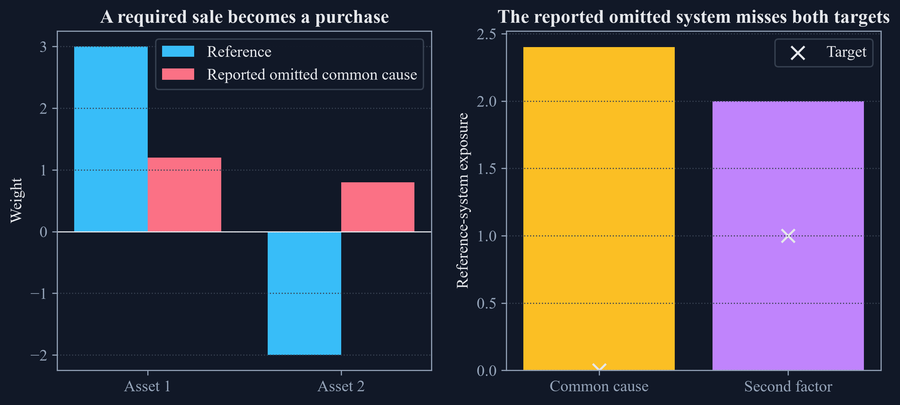

In [2]:
figure, axes = plt.subplots(1, 2, figsize=(10.6, 4.4))
source_locations = np.arange(2)
axes[0].bar(source_locations - 0.19, source_reference_weights, width=0.38, color=palette["cyan"], label="Reference")
axes[0].bar(source_locations + 0.19, source_reported_misspecified_weights, width=0.38, color=palette["rose"], label="Reported omitted common cause")
axes[0].axhline(0.0, color=palette["text"], linewidth=0.8)
axes[0].set_xticks(source_locations)
axes[0].set_xticklabels(["Asset 1", "Asset 2"])
axes[0].set_ylabel("Weight")
axes[0].set_title("A required sale becomes a purchase")
axes[0].legend()
axes[0].grid(True, axis="y")
axes[1].bar(["Common cause", "Second factor"], source_reported_achieved, color=[palette["amber"], palette["violet"]])
axes[1].scatter(["Common cause", "Second factor"], source_reference_targets, color=palette["text"], marker="x", s=90, label="Target")
axes[1].set_ylabel("Reference-system exposure")
axes[1].set_title("The reported omitted system misses both targets")
axes[1].legend()
axes[1].grid(True, axis="y")
save_figure(figure, "misspecification_source_confounder")

## Public Covariance with Supplied Exposure Systems

The public covariance can measure the risk of each supplied portfolio, while the exposure error remains defined by the chosen reference system:

$$
\widehat\sigma_R^2=w_R^{\mathsf T}\widehat Vw_R,
\qquad
\widehat\sigma_M^2=w_M^{\mathsf T}\widehat Vw_M,
\qquad
\operatorname{RMSE}(e_R)=\sqrt{\frac{1}{K}\sum_{k=1}^{K}e_{R,k}^2}.
$$

Here, $\widehat V$ is the annualized covariance estimated from public industry returns, $w_R$ and $w_M$ are the two supplied-system portfolios, $\widehat\sigma_R^2$ and $\widehat\sigma_M^2$ are their estimated variances, $K$ is the number of reference constraints, and $e_{R,k}$ is the error in reference exposure $k$.

### Public covariance data used for the allocation comparison

In [3]:
public_assets = list(industry_returns.columns[:12])
public_sample = industry_returns[public_assets]
public_covariance = public_sample.cov().to_numpy() * 252.0
public_count = len(public_assets)
public_rng = np.random.default_rng(2702)
supplied_reference_factors = public_rng.normal(size=(public_count, 2))
supplied_reference_factors = supplied_reference_factors - supplied_reference_factors.mean(axis=0)
supplied_reference_factors = supplied_reference_factors / supplied_reference_factors.std(axis=0, ddof=1)
supplied_reference = np.column_stack([np.ones(public_count), supplied_reference_factors])
supplied_targets = np.array([1.0, 0.25, -0.15])
supplied_misspecified = supplied_reference.copy()
supplied_misspecified[:, 1:] = supplied_misspecified[:, 1:] + 0.35 * public_rng.normal(size=(public_count, 2))
public_result = allocation_misspecification_diagnostics(public_covariance, supplied_reference, supplied_targets, supplied_misspecified, supplied_targets)
public_data_table = pd.DataFrame({'Field': ['Archive', 'Provider', 'Analysis start', 'Analysis end', 'Complete dates', 'Industry portfolios'], 'Value': ['49 Industry Portfolios daily archive', 'Kenneth R. French Data Library', str(public_sample.index.min().date()), str(public_sample.index.max().date()), len(public_sample), public_sample.shape[1]]})
save_table(public_data_table, 'misspecification_data_provenance', 'Public covariance data used for the allocation comparison.', 'tab:chapter27-misspecification-data')
display(public_data_table)
public_weight_table = pd.DataFrame({'Industry': public_assets, 'Reference weight': public_result.reference_weights, 'Misspecified weight': public_result.misspecified_weights, 'Sign reversal': public_result.weight_sign_reversals})
save_table(public_weight_table, 'misspecification_public_weights', 'Weights obtained from two supplied exposure systems under the same public covariance.', 'tab:chapter27-misspecification-public-weights')
display(public_weight_table)
public_exposure_table = pd.DataFrame({'Reference constraint': ['Budget', 'Supplied exposure one', 'Supplied exposure two'], 'Target': supplied_targets, 'Reference achieved': public_result.reference_achieved_exposures, 'Misspecified achieved in reference system': public_result.misspecified_reference_exposures, 'Exposure error': public_result.reference_exposure_error})
save_table(public_exposure_table, 'misspecification_public_exposures', 'Reference-system exposure errors under the perturbed supplied system.', 'tab:chapter27-misspecification-public-exposures')
display(public_exposure_table)
public_summary = pd.DataFrame([{'Quantity': 'Reference variance', 'Value': public_result.reference_variance}, {'Quantity': 'Misspecified variance', 'Value': public_result.misspecified_variance}, {'Quantity': 'Exposure error root mean square', 'Value': np.sqrt(np.mean(public_result.reference_exposure_error ** 2))}, {'Quantity': 'Sign reversals', 'Value': int(public_result.weight_sign_reversals.sum())}, {'Quantity': 'Reference gross exposure', 'Value': np.abs(public_result.reference_weights).sum()}, {'Quantity': 'Misspecified gross exposure', 'Value': np.abs(public_result.misspecified_weights).sum()}])
save_table(public_summary, 'misspecification_public_summary', 'Summary of the public covariance allocation comparison.', 'tab:chapter27-misspecification-public-summary')
display(public_summary);


,Field,Value
0,Archive,49 Industry Portfolios daily archive
1,Provider,Kenneth R. French Data Library
2,Analysis start,2019-01-02
3,Analysis end,2025-12-31
4,Complete dates,1760
5,Industry portfolios,12


,Industry,Reference weight,Misspecified weight,Sign reversal
0,Agric,0.03364,0.024331,False
1,Food,0.045886,0.111785,False
2,Soda,0.301335,0.288828,False
3,Beer,0.073771,0.033601,False
4,Smoke,0.097594,0.087958,False
5,Toys,-0.006763,-0.009901,False
6,Fun,0.103377,0.099388,False
7,Books,0.078354,0.105806,False
8,Hshld,0.320926,0.338074,False
9,Clths,-0.086052,-0.08632,False


,Reference constraint,Target,Reference achieved,Misspecified achieved in reference system,Exposure error
0,Budget,1,1,1,0
1,Supplied exposure one,0.25,0.25,0.09306,-0.15694
2,Supplied exposure two,-0.15,-0.15,0.007269,0.157269


,Quantity,Value
0,Reference variance,0.026798
1,Misspecified variance,0.026237
2,Exposure error root mean square,0.128276
3,Sign reversals,1
4,Reference gross exposure,1.18563
5,Misspecified gross exposure,1.210576


### Same covariance, different supplied exposures

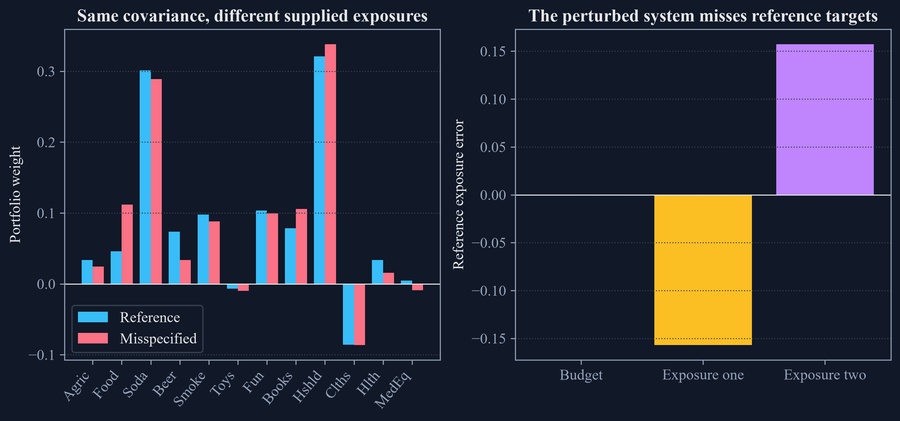

In [3]:
figure, axes = plt.subplots(1, 2, figsize=(11.4, 4.6))
locations = np.arange(public_count)
axes[0].bar(locations - 0.19, public_result.reference_weights, width=0.38, color=palette['cyan'], label='Reference')
axes[0].bar(locations + 0.19, public_result.misspecified_weights, width=0.38, color=palette['rose'], label='Misspecified')
axes[0].axhline(0.0, color=palette['text'], linewidth=0.8)
axes[0].set_xticks(locations)
axes[0].set_xticklabels(public_assets, rotation=50, ha='right')
axes[0].set_ylabel('Portfolio weight')
axes[0].set_title('Same covariance, different supplied exposures')
axes[0].legend()
axes[0].grid(True, axis='y')
axes[1].bar(['Budget', 'Exposure one', 'Exposure two'], public_result.reference_exposure_error, color=[palette['muted'], palette['amber'], palette['violet']])
axes[1].axhline(0.0, color=palette['text'], linewidth=0.8)
axes[1].set_ylabel('Reference exposure error')
axes[1].set_title('The perturbed system misses reference targets')
axes[1].grid(True, axis='y')
save_figure(figure, 'misspecification_public_weights_errors')


## Repeated Misspecification Experiments

Across repeated known-system experiments, exposure error and the rate of sign changes are summarized by:

$$
\widehat E_s=\frac{1}{M}\sum_{m=1}^{M}\sqrt{\frac{1}{K}\sum_{k=1}^{K}e_{m,k}^2},
\qquad
\widehat R_s=\frac{1}{MN}\sum_{m=1}^{M}\sum_{n=1}^{N}\mathbf 1\{w_{R,m,n}w_{M,m,n}<0\}.
$$

Here, $s$ is the size of the exposure perturbation, $M$ is the number of generated systems, $K$ is the number of reference constraints, $N$ is the number of assets, $e_{m,k}$ is exposure error $k$ in repetition $m$, $w_{R,m,n}$ and $w_{M,m,n}$ are the two weights for asset $n$, and $\mathbf 1\{\cdot\}$ equals one when its condition is true.

### Average diagnostics across 30 fixed-seed exposure perturbations

In [4]:
perturbation_levels = [0.0, 0.05, 0.10, 0.20, 0.40, 0.80]
repeated_rows = []
scatter_rows = []
for level in perturbation_levels:
    for repetition in range(30):
        repeated_rng = np.random.default_rng(270200 + repetition)
        perturbation = repeated_rng.normal(size=(public_count, 2))
        misspecified = supplied_reference.copy()
        misspecified[:, 1:] = misspecified[:, 1:] + level * perturbation
        result = allocation_misspecification_diagnostics(public_covariance, supplied_reference, supplied_targets, misspecified, supplied_targets)
        repeated_rows.append({"Perturbation size": level, "Repetition": repetition, "Exposure error root mean square": np.sqrt(np.mean(result.reference_exposure_error ** 2)), "Sign reversal fraction": result.weight_sign_reversals.mean(), "Variance ratio": result.misspecified_variance / result.reference_variance, "Gross exposure ratio": np.abs(result.misspecified_weights).sum() / np.abs(result.reference_weights).sum()})
        if level == 0.40:
            for asset_index in range(public_count):
                scatter_rows.append({"Reference weight": result.reference_weights[asset_index], "Misspecified weight": result.misspecified_weights[asset_index], "Sign reversal": result.weight_sign_reversals[asset_index]})
repeated_frame = pd.DataFrame(repeated_rows)
perturbation_summary = repeated_frame.groupby("Perturbation size", as_index=False).agg({"Exposure error root mean square": "mean", "Sign reversal fraction": "mean", "Variance ratio": "mean", "Gross exposure ratio": "mean"})
save_table(perturbation_summary, "misspecification_perturbation_summary", "Average diagnostics across 30 fixed-seed exposure perturbations.", "tab:chapter27-misspecification-perturbation-summary")
display(perturbation_summary)

worst_cases = repeated_frame.sort_values("Exposure error root mean square", ascending=False).head(10).reset_index(drop=True)
save_table(worst_cases, "misspecification_worst_cases", "Ten largest exposure errors in the repeated experiment.", "tab:chapter27-misspecification-worst-cases")
display(worst_cases);



,Perturbation size,Exposure error root mean square,Sign reversal fraction,Variance ratio,Gross exposure ratio
0,0,0,0,1,1
1,0.05,0.018217,0.011111,1.000867,0.999185
2,0.1,0.035748,0.019444,1.001683,0.999641
3,0.2,0.06843,0.058333,1.003137,1.003732
4,0.4,0.124955,0.113889,1.00508,1.029084
5,0.8,0.229235,0.141667,1.003236,1.082547


,Perturbation size,Repetition,Exposure error root mean square,Sign reversal fraction,Variance ratio,Gross exposure ratio
0,0.8,18,0.640399,0.083333,0.935035,1.242023
1,0.8,26,0.541392,0,0.960593,1.003521
2,0.8,9,0.530912,0.166667,0.940996,1.130933
3,0.8,24,0.405294,0.25,0.951481,1.224698
4,0.8,13,0.348971,0.333333,0.963722,1.113838
5,0.8,25,0.318007,0.333333,0.99062,1.018676
6,0.4,26,0.311598,0,0.976073,0.998335
7,0.8,15,0.310459,0.166667,0.999737,0.954099
8,0.4,18,0.305742,0.166667,0.964072,1.105577
9,0.8,19,0.301942,0.083333,0.963648,1.067562


### Reference exposure error

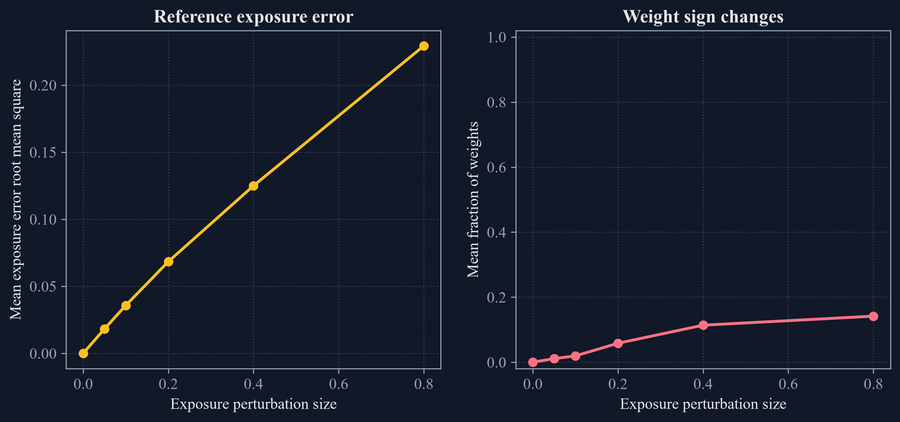

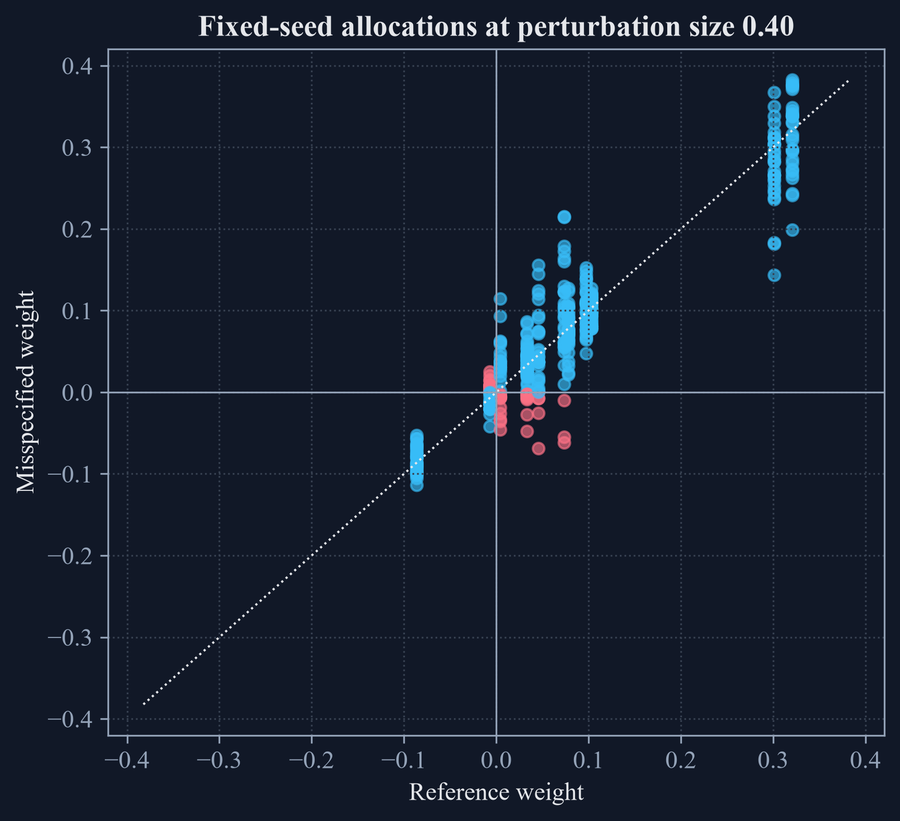

In [4]:
figure, axes = plt.subplots(1, 2, figsize=(10.9, 4.5))
axes[0].plot(perturbation_summary["Perturbation size"], perturbation_summary["Exposure error root mean square"], marker="o", color=palette["amber"], linewidth=2.1, label="Exposure error")
axes[0].set_xlabel("Exposure perturbation size")
axes[0].set_ylabel("Mean exposure error root mean square")
axes[0].set_title("Reference exposure error")
axes[0].grid(True)
axes[1].plot(perturbation_summary["Perturbation size"], perturbation_summary["Sign reversal fraction"], marker="o", color=palette["rose"], linewidth=2.1, label="Sign reversal fraction")
axes[1].set_xlabel("Exposure perturbation size")
axes[1].set_ylabel("Mean fraction of weights")
axes[1].set_ylim(-0.02, 1.02)
axes[1].set_title("Weight sign changes")
axes[1].grid(True)
save_figure(figure, "misspecification_perturbation_paths")

scatter_frame = pd.DataFrame(scatter_rows)
figure, axis = plt.subplots(figsize=(6.4, 5.7))
colors = np.where(scatter_frame["Sign reversal"], palette["rose"], palette["cyan"])
axis.scatter(scatter_frame["Reference weight"], scatter_frame["Misspecified weight"], c=colors, alpha=0.65, s=28)
bounds = np.nanmax(np.abs(scatter_frame[["Reference weight", "Misspecified weight"]].to_numpy()))
axis.plot([-bounds, bounds], [-bounds, bounds], color=palette["text"], linewidth=1.0, linestyle=":")
axis.axhline(0.0, color=palette["muted"], linewidth=0.8)
axis.axvline(0.0, color=palette["muted"], linewidth=0.8)
axis.set_xlabel("Reference weight")
axis.set_ylabel("Misspecified weight")
axis.set_title("Fixed-seed allocations at perturbation size 0.40")
axis.grid(True)
save_figure(figure, "misspecification_weight_scatter")

## Interpreting optimization results at their boundaries

A common positive change in covariance units preserves both weight vectors and multiplies both reported variances by the same amount:

$$
w_R(sV)=w_R(V),
\qquad
w_M(sV)=w_M(V),
\qquad
\sigma_R^2(sV)=s\sigma_R^2(V),
\qquad
\sigma_M^2(sV)=s\sigma_M^2(V).
$$

Here, $s>0$ is a change in covariance units, $w_R$ and $w_M$ are the reference and misspecified weights, and $\sigma_R^2$ and $\sigma_M^2$ are their portfolio variances under the stated covariance matrix.

### Covariance-unit checks for allocation diagnostics

In [5]:
rescaled_result = allocation_misspecification_diagnostics(7.5 * released_covariance, released_reference_exposures, released_reference_targets, released_misspecified_exposures, released_misspecified_targets)
invariance_table = pd.DataFrame([
    {"Check": "Reference weights", "Largest difference": np.max(np.abs(rescaled_result.reference_weights - released_result.reference_weights)), "Expected scale": 1.0, "Observed scale": 1.0, "Passed": np.allclose(rescaled_result.reference_weights, released_result.reference_weights)},
    {"Check": "Misspecified weights", "Largest difference": np.max(np.abs(rescaled_result.misspecified_weights - released_result.misspecified_weights)), "Expected scale": 1.0, "Observed scale": 1.0, "Passed": np.allclose(rescaled_result.misspecified_weights, released_result.misspecified_weights)},
    {"Check": "Reference variance", "Largest difference": abs(rescaled_result.reference_variance - 7.5 * released_result.reference_variance), "Expected scale": 7.5, "Observed scale": rescaled_result.reference_variance / released_result.reference_variance, "Passed": np.isclose(rescaled_result.reference_variance, 7.5 * released_result.reference_variance)},
    {"Check": "Misspecified variance", "Largest difference": abs(rescaled_result.misspecified_variance - 7.5 * released_result.misspecified_variance), "Expected scale": 7.5, "Observed scale": rescaled_result.misspecified_variance / released_result.misspecified_variance, "Passed": np.isclose(rescaled_result.misspecified_variance, 7.5 * released_result.misspecified_variance)},
])
save_table(invariance_table, "misspecification_invariance", "Covariance-unit checks for allocation diagnostics.", "tab:chapter27-misspecification-invariance")
display(invariance_table)

identity_exposures = np.eye(2)
strict_boundary = allocation_misspecification_diagnostics(np.eye(2), identity_exposures, [1.0, 0.0], identity_exposures, [-1.0, 0.0])
zero_boundary = allocation_misspecification_diagnostics(np.eye(2), identity_exposures, [0.0, 1.0], identity_exposures, [-1.0, 1.0])
boundary_table = pd.DataFrame([
    {"Case": "Strict opposite nonzero signs", "Reference first weight": strict_boundary.reference_weights[0], "Misspecified first weight": strict_boundary.misspecified_weights[0], "First weight is a reversal": strict_boundary.weight_sign_reversals[0]},
    {"Case": "Reference weight equals zero", "Reference first weight": zero_boundary.reference_weights[0], "Misspecified first weight": zero_boundary.misspecified_weights[0], "First weight is a reversal": zero_boundary.weight_sign_reversals[0]},
])
save_table(boundary_table, "misspecification_sign_boundaries", "Strict sign-reversal rule at and away from zero.", "tab:chapter27-misspecification-sign-boundaries")
display(boundary_table)

input_checks = pd.DataFrame([
    contract_result("Boolean covariance", lambda: allocation_misspecification_diagnostics(np.array([[True, False], [False, True]]), np.eye(2), [1.0, 0.0], np.eye(2), [1.0, 0.0]), "ValueError"),
    contract_result("Nonfinite covariance", lambda: allocation_misspecification_diagnostics(np.array([[1.0, 0.0], [0.0, np.nan]]), np.eye(2), [1.0, 0.0], np.eye(2), [1.0, 0.0]), "ValueError"),
    contract_result("Complex reference exposures", lambda: allocation_misspecification_diagnostics(np.eye(2), np.array([[1.0 + 1.0j, 0.0], [0.0, 1.0]]), [1.0, 0.0], np.eye(2), [1.0, 0.0]), "ValueError"),
    contract_result("Wrong reference rows", lambda: allocation_misspecification_diagnostics(np.eye(2), np.ones((3, 1)), [1.0], np.ones((2, 1)), [1.0]), "ValueError"),
    contract_result("Too many misspecified columns", lambda: allocation_misspecification_diagnostics(np.eye(2), np.eye(2), [1.0, 0.0], np.ones((2, 3)), [1.0, 0.0, 0.0]), "ValueError"),
    contract_result("Redundant reference columns", lambda: allocation_misspecification_diagnostics(np.eye(3), np.array([[1.0, 1.0], [0.0, 0.0], [1.0, 1.0]]), [1.0, 0.0], np.ones((3, 1)), [1.0]), "ValueError"),
])
save_table(input_checks, "misspecification_input_checks", "Rejected inputs at the public diagnostic boundary.", "tab:chapter27-misspecification-input")
display(input_checks);



,Check,Largest difference,Expected scale,Observed scale,Passed
0,Reference weights,0,1,1,True
1,Misspecified weights,0,1,1,True
2,Reference variance,0,7.5,7.5,True
3,Misspecified variance,0,7.5,7.5,True


,Case,Reference first weight,Misspecified first weight,First weight is a reversal
0,Strict opposite nonzero signs,1,-1,True
1,Reference weight equals zero,0,-1,False


,Check,Expected result,Observed result,Passed
0,Boolean covariance,ValueError,ValueError,True
1,Nonfinite covariance,ValueError,ValueError,True
2,Complex reference exposures,ValueError,ValueError,True
3,Wrong reference rows,ValueError,ValueError,True
4,Too many misspecified columns,ValueError,ValueError,True
5,Redundant reference columns,ValueError,ValueError,True


### Immutability checks for returned diagnostic evidence

In [5]:
record_rows = []
for field in ["reference_weights", "misspecified_weights", "reference_exposure_error", "weight_sign_reversals"]:
    value = getattr(released_result, field)
    record_rows.append({"Returned field": field.replace("_", " ").title(), "Read only": not value.flags.writeable, "Independent memory": not np.shares_memory(value, released_reference_exposures), "Passed": not value.flags.writeable and not np.shares_memory(value, released_reference_exposures)})
try:
    released_result.reference_variance = 0.0
    frozen_passed = False
except FrozenInstanceError:
    frozen_passed = True
record_rows.append({"Returned field": "Result record", "Read only": frozen_passed, "Independent memory": True, "Passed": frozen_passed})
record_table = pd.DataFrame(record_rows)
save_table(record_table, "misspecification_record_checks", "Immutability checks for returned diagnostic evidence.", "tab:chapter27-misspecification-record")
display(record_table)

public_surface = pd.DataFrame([
    {"Public group": "Allocation diagnostic function", "Count": 1, "Coverage": "Two supplied systems, target checks, exposure errors, sign changes, and variance"},
    {"Public group": "Allocation diagnostic result record", "Count": 1, "Coverage": "Independent read-only evidence"},
    {"Public group": "Released diagnostic checks", "Count": 9, "Coverage": "Oracles, units, boundaries, immutability, invalid inputs, and input preservation"},
])
save_table(public_surface, "misspecification_public_surface", "Released public diagnostic material covered by Section 27.2.", "tab:chapter27-misspecification-public-surface")
display(public_surface)

section_summary = pd.DataFrame([
    {"Evidence": "Target exposure error", "What it shows": "Consequences of using one supplied system under another", "What it does not show": "Which system is causally correct"},
    {"Evidence": "Weight sign reversal", "What it shows": "The two supplied systems imply opposite positions", "What it does not show": "That either system was learned correctly"},
    {"Evidence": "Variance difference", "What it shows": "Risk under the common covariance estimate", "What it does not show": "Whether required exposures were met"},
    {"Evidence": "Repeated generated systems", "What it shows": "Sensitivity when the reference is known by construction", "What it does not show": "Truth for an observed market"},
])
save_table(section_summary, "misspecification_section_summary", "Interpretation of the allocation diagnostics.", "tab:chapter27-misspecification-section-summary")
display(section_summary)

,Returned field,Read only,Independent memory,Passed
0,Reference Weights,True,True,True
1,Misspecified Weights,True,True,True
2,Reference Exposure Error,True,True,True
3,Weight Sign Reversals,True,True,True
4,Result record,True,True,True


,Public group,Count,Coverage
0,Allocation diagnostic function,1,"Two supplied systems, target checks, exposure ..."
1,Allocation diagnostic result record,1,Independent read-only evidence
2,Released diagnostic checks,9,"Oracles, units, boundaries, immutability, inva..."


,Evidence,What it shows,What it does not show
0,Target exposure error,Consequences of using one supplied system unde...,Which system is causally correct
1,Weight sign reversal,The two supplied systems imply opposite positions,That either system was learned correctly
2,Variance difference,Risk under the common covariance estimate,Whether required exposures were met
3,Repeated generated systems,Sensitivity when the reference is known by con...,Truth for an observed market


## Tests

In [6]:
np.testing.assert_allclose(released_result.reference_weights, [-2.0 / 7.0, 5.0 / 7.0, 2.0 / 7.0], atol=2e-15)
np.testing.assert_allclose(released_result.misspecified_weights, [0.4, 0.2, -0.2], atol=2e-15)
np.testing.assert_allclose(released_result.reference_exposure_error, [0.2, -1.0], atol=2e-15)
np.testing.assert_array_equal(released_result.weight_sign_reversals, [True, False, True])
np.testing.assert_allclose(source_reference_weights, [3.0, -2.0], atol=2e-14)
np.testing.assert_allclose(source_reported_misspecified_weights, [1.2, 0.8], atol=2e-14)
np.testing.assert_allclose(source_exposure_error, [2.4, 1.0], atol=2e-14)
assert source_sign_reversals[1]
np.testing.assert_allclose(public_result.reference_achieved_exposures, supplied_targets, atol=2e-12)
np.testing.assert_allclose(public_result.misspecified_model_achieved_exposures, supplied_targets, atol=2e-12)
assert perturbation_summary.loc[perturbation_summary['Perturbation size'] == 0.0, 'Exposure error root mean square'].iloc[0] < 1e-12
assert invariance_table['Passed'].all()
assert input_checks['Passed'].all()
assert record_table['Passed'].all()
assert public_surface['Count'].sum() == 11
assert isinstance(released_result, AllocationMisspecificationDiagnostics)
for stem in ['misspecification_released_example', 'misspecification_source_confounder', 'misspecification_public_weights_errors', 'misspecification_perturbation_paths', 'misspecification_weight_scatter']:
    assert (FIGURES / f'{stem}.pdf').is_file()
for stem in ['misspecification_released_weights', 'misspecification_released_exposures', 'misspecification_released_variances', 'misspecification_source_weights', 'misspecification_source_exposures', 'misspecification_source_variances', 'misspecification_data_provenance', 'misspecification_public_weights', 'misspecification_public_exposures', 'misspecification_public_summary', 'misspecification_perturbation_summary', 'misspecification_worst_cases', 'misspecification_invariance', 'misspecification_sign_boundaries', 'misspecification_input_checks', 'misspecification_record_checks', 'misspecification_public_surface', 'misspecification_section_summary']:
    assert (TABLES / f'{stem}.tex').is_file()
